
# Penghitung Jumlah Koin Menggunakan OpenCV

Proyek ini bertujuan untuk mendeteksi dan menghitung jumlah koin pada gambar menggunakan teknik *computer vision* dengan Python dan OpenCV.

Anggota :

Sausan Irtiyaah (2408107010048)

Iftitah Putri Syahna (2408107010065)

Brigita Hafidzah Agnil (2408107010066)

## 1. Instalasi library

In [44]:
%pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import library

In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import Request, urlopen

## 3. Membaca gambar dari URL

kode ini nantinya mengambil gambar koin dari URL, kemudian membaca gambar agar dapat diproses menggunakan OpenCV.

Gambar berhasil dibaca.
Ukuran gambar: 960 x 1280


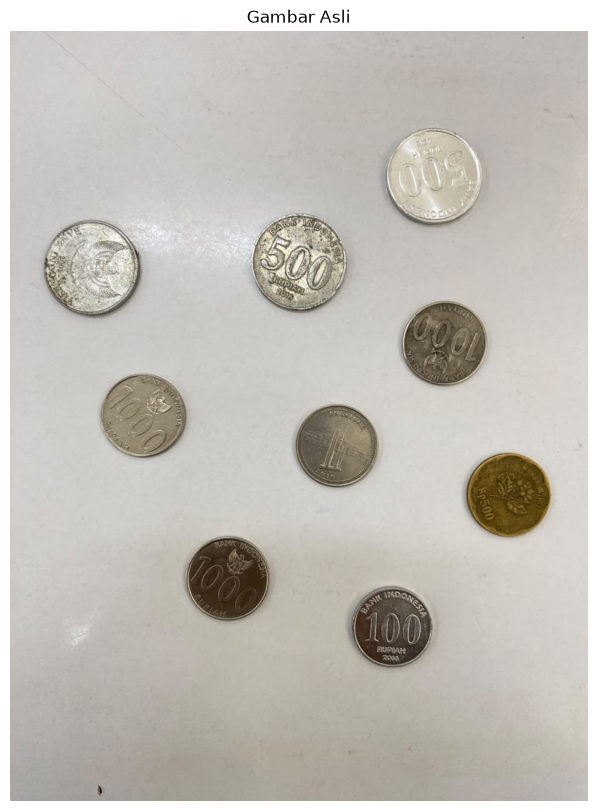

In [46]:
url_gambar = "https://i.ibb.co.com/d8tc517/koin2.jpg".strip()

if not url_gambar:
    raise ValueError("URL gambar masih kosong. Tempelkan URL gambar setelah prompt muncul.")

request = Request(url_gambar, headers={"User-Agent": "Mozilla/5.0"})
with urlopen(request, timeout=20) as response:
    data_gambar = np.frombuffer(response.read(), dtype=np.uint8)

gambar = cv2.imdecode(data_gambar, cv2.IMREAD_COLOR)

if gambar is None:
    raise ValueError("Gambar gagal dibaca. Pastikan URL mengarah langsung ke file gambar publik.")

print("Gambar berhasil dibaca.")
print("Ukuran gambar:", gambar.shape[1], "x", gambar.shape[0])

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB))
plt.title("Gambar Asli")
plt.axis("off")
plt.show()


## 4. Grayscale dan peningkatan kontras
Citra diubah menjadi grayscale. `equalizeHist` merupakan histogram equalization yang dapat membantu saat kontras citra rendah.

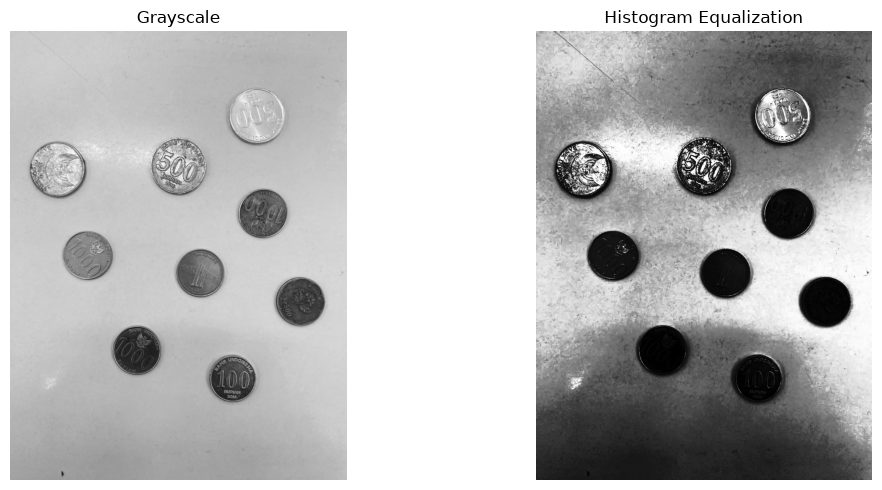

In [47]:
abu_abu = cv2.cvtColor(gambar, cv2.COLOR_BGR2GRAY)
kontras = cv2.equalizeHist(abu_abu)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(abu_abu, cmap="gray")
axes[0].set_title("Grayscale")
axes[0].axis("off")
axes[1].imshow(kontras, cmap="gray")
axes[1].set_title("Histogram Equalization")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 5. Mengurangi noise dan melihat tepi
pada kode ini digunakan Median Blur untuk mengurangi gangguan kecil pada gambar sebelum proses deteksi lingkaran. Dan digunakan metode Canny untuk mendeteksi tepi objek sebagai salah satu tahap pengolahan gambar.

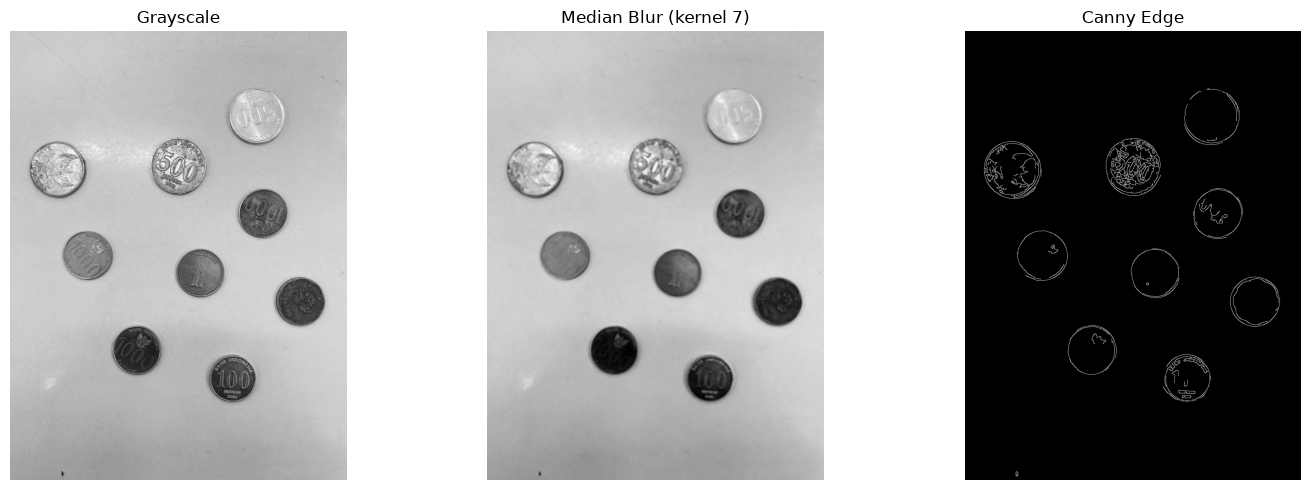

In [48]:
# Gunakan grayscale asli yang dihaluskan untuk deteksi
blur = cv2.medianBlur(abu_abu, 7)
tepi = cv2.Canny(blur, 50, 150)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(abu_abu, cmap="gray")
axes[0].set_title("Grayscale")
axes[0].axis("off")
axes[1].imshow(blur, cmap="gray")
axes[1].set_title("Median Blur (kernel 7)")
axes[1].axis("off")
axes[2].imshow(tepi, cmap="gray")
axes[2].set_title("Canny Edge")
axes[2].axis("off")
plt.tight_layout()
plt.show()


## 6. Mendeteksi lingkaran

Menggunakan metode Hough Circle Transform untuk mendeteksi lingkaran pada gambar. Parameter deteksi disesuaikan agar lingkaran yang ditemukan mendekati bentuk dan ukuran koin.


In [49]:
# Parameter awal 
min_radius = 50
max_radius = 100
min_jarak = 90

param1 = 120
param2 = 45

lingkaran = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=min_jarak,
    param1=param1,
    param2=param2,
    minRadius=min_radius,
    maxRadius=max_radius
)

koin = []
if lingkaran is not None:
    lingkaran = np.round(lingkaran[0]).astype(int)
    koin = [(int(x), int(y), int(r)) for x, y, r in lingkaran]

print("Jumlah lingkaran/koin terdeteksi:", len(koin))


Jumlah lingkaran/koin terdeteksi: 9


## 7. Menampilkan hasil deteksi
Lingkaran hijau menunjukkan hasil deteksi dan titik merah menunjukkan pusat lingkaran. Nomor menunjukkan perhitungan koin.


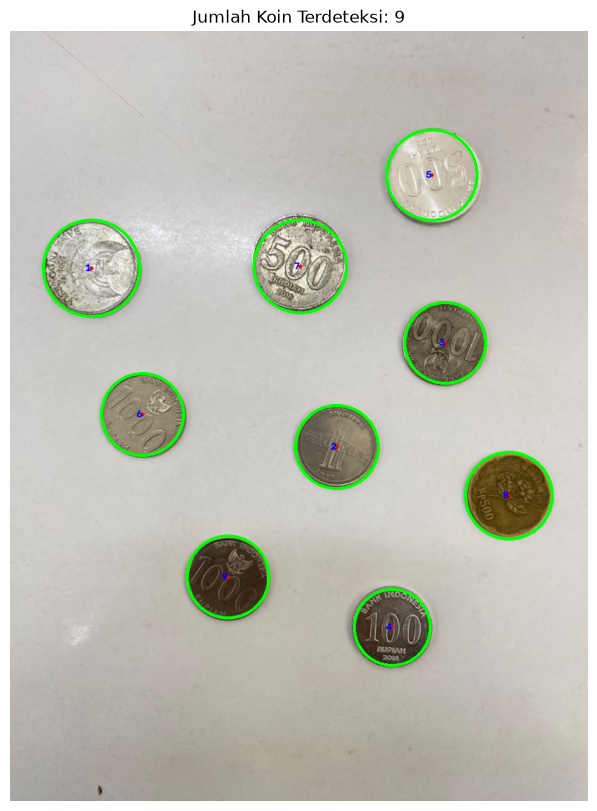

In [50]:
hasil = gambar.copy()

for nomor, (x, y, radius) in enumerate(koin, start=1):
    cv2.circle(hasil, (x, y), radius, (0, 255, 0), 3)
    cv2.circle(hasil, (x, y), 3, (0, 0, 255), -1)
    cv2.putText(
        hasil, str(nomor), (x - 10, y + 5),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2
    )

hasil_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 10))
plt.imshow(hasil_rgb)
plt.title(f"Jumlah Koin Terdeteksi: {len(koin)}")
plt.axis("off")
plt.show()


## 8. Menyimpan hasil


In [51]:
nama_file = "hasil_deteksi_koin.jpg"
berhasil = cv2.imwrite(nama_file, hasil)

if berhasil:
    print("Hasil disimpan sebagai:", nama_file)
else:
    print("Gambar hasil gagal disimpan.")

Hasil disimpan sebagai: hasil_deteksi_koin.jpg
